# Exact ray tracing through lenses and mirrors

This notebook uses `raytrace` to trace real (non-paraxial) rays and show the aberrations that first-order optics leaves out:

1. a ray fan through a biconvex BK7 lens,
2. why a plano-convex lens should face its curved side to collimated light,
3. the caustic of a spherical mirror, checked against the exact formula,
4. axial colour: glass dispersion and the focal shift of a singlet,
5. spot diagrams at the paraxial and best focus.

All lengths are in millimetres.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import raytrace as rt

## 1. Ray fan through a biconvex lens

EFL = 50.835 mm, lensmaker = 50.835 mm, BFD = 48.817 mm


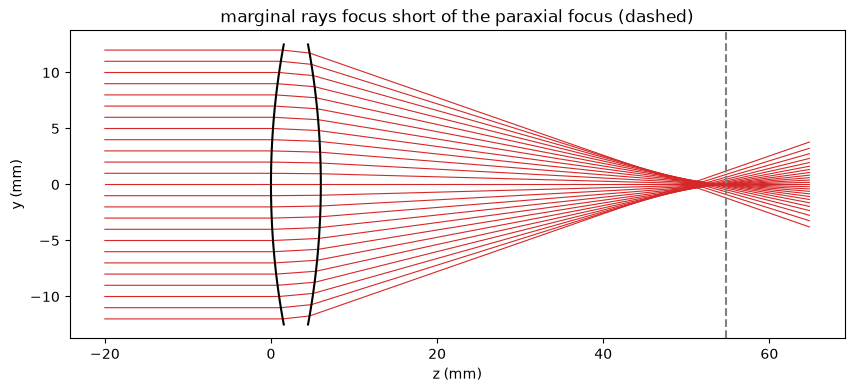

In [2]:
lens = rt.OpticalSystem(rt.singlet(51.5, -51.5, 6.0, rt.BK7, aperture=12.5))
f = lens.efl()
print(f"EFL = {f:.3f} mm, lensmaker = {rt.lensmaker_efl(51.5, -51.5, 6.0, rt.BK7.n(rt.LINE_D)):.3f} mm, BFD = {lens.back_focal_distance():.3f} mm")
ys = np.linspace(-12, 12, 25)
b = lens.trace(np.column_stack([np.zeros_like(ys), ys, np.full_like(ys, -20.0)]),
               np.tile([0, 0, 1.0], (ys.size, 1)), record=True)
z_end = lens.paraxial_focus() + 10
plt.figure(figsize=(10, 4))
for k in range(ys.size):
    zs = [p[k, 2] for p in b.path] + [z_end]
    yy = [p[k, 1] for p in b.path] + [b.pos[k, 1] + (z_end - b.pos[k, 2]) * b.dir[k, 1] / b.dir[k, 2]]
    plt.plot(zs, yy, lw=0.8, c="tab:red")
zz = np.linspace(-12.5, 12.5, 100)
for s in lens.surfaces:
    plt.plot(s.z + (s.R - np.sign(s.R) * np.sqrt(s.R**2 - zz**2)), zz, "k")
plt.axvline(lens.paraxial_focus(), ls="--", c="gray")
plt.xlabel("z (mm)"); plt.ylabel("y (mm)"); plt.title("marginal rays focus short of the paraxial focus (dashed)")
plt.show()

## 2. Plano-convex lens: which way round?

The two orientations have the same focal length. Facing the curved side to the collimated beam splits the bending between both surfaces, which cuts spherical aberration by about 4×.

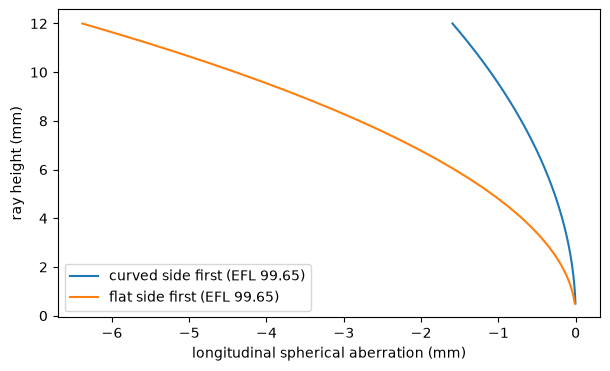

SA at h = 12 mm: curved first -1.594 mm, flat first -6.383 mm


In [3]:
good = rt.OpticalSystem(rt.singlet(51.5, np.inf, 6.0, rt.BK7))
bad = rt.OpticalSystem(rt.singlet(np.inf, -51.5, 6.0, rt.BK7))
h = np.linspace(0.5, 12, 30)
plt.figure(figsize=(7, 4))
plt.plot([good.longitudinal_sa(x) for x in h], h, label=f"curved side first (EFL {good.efl():.2f})")
plt.plot([bad.longitudinal_sa(x) for x in h], h, label=f"flat side first (EFL {bad.efl():.2f})")
plt.xlabel("longitudinal spherical aberration (mm)"); plt.ylabel("ray height (mm)"); plt.legend(); plt.show()
print(f"SA at h = 12 mm: curved first {good.longitudinal_sa(12):.3f} mm, flat first {bad.longitudinal_sa(12):.3f} mm")

## 3. Caustic of a spherical mirror

A ray at height $h$ crosses the axis at $z = -R + R/(2\cos\theta)$ with $\sin\theta = h/R$.

max |trace - exact| = 2.1316282072803006e-14 mm


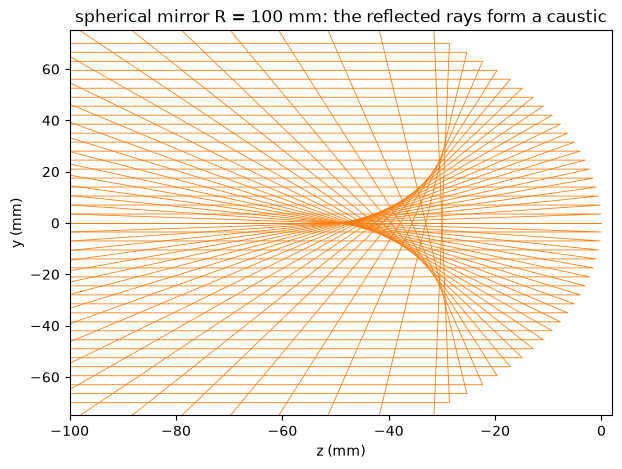

In [4]:
R = 100.0
mirror = rt.OpticalSystem([rt.Surface(0.0, -R, mirror=True)])
hs = np.linspace(1, 70, 40)
z_trace = [mirror.axis_crossing(x) for x in hs]
z_exact = -R + R / (2 * np.cos(np.arcsin(hs / R)))
print("max |trace - exact| =", np.max(np.abs(np.array(z_trace) - z_exact)), "mm")
plt.figure(figsize=(7, 5))
for x in np.linspace(-70, 70, 41):
    bb = mirror.trace([[0, x, -R - 1]], [[0, 0, 1.0]])
    p, d = bb.pos[0], bb.dir[0]
    t = (-R - p[2]) / d[2]
    plt.plot([-R - 1, p[2], p[2] + t * d[2]], [x, p[1], p[1] + t * d[1]], c="tab:orange", lw=0.6)
plt.xlim(-R, 2); plt.ylim(-75, 75); plt.xlabel("z (mm)"); plt.ylabel("y (mm)")
plt.title("spherical mirror R = 100 mm: the reflected rays form a caustic"); plt.show()

## 4. Dispersion and axial colour

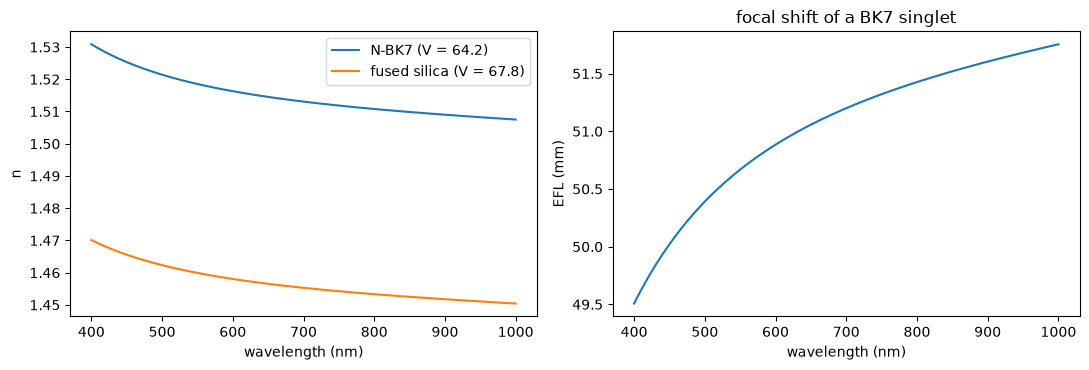

In [5]:
wl = np.linspace(0.4, 1.0, 200)
lens2 = rt.singlet(51.5, -51.5, 6.0, rt.BK7)
efl = [rt.OpticalSystem(lens2, wavelength_um=w).efl() for w in wl]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(wl * 1000, rt.BK7.n(wl), label=f"N-BK7 (V = {rt.abbe_number(rt.BK7):.1f})")
axes[0].plot(wl * 1000, rt.FUSED_SILICA.n(wl), label=f"fused silica (V = {rt.abbe_number(rt.FUSED_SILICA):.1f})")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("n"); axes[0].legend()
axes[1].plot(wl * 1000, efl); axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("EFL (mm)")
axes[1].set_title("focal shift of a BK7 singlet")
plt.tight_layout(); plt.show()

## 5. Spot diagrams

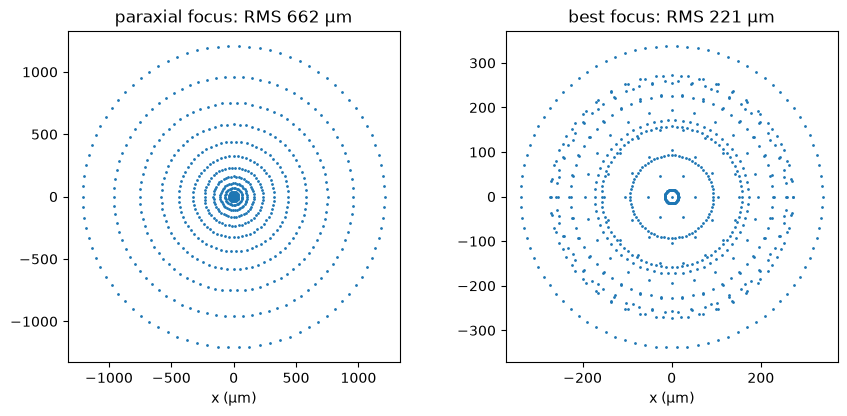

best focus is 3.375 mm in front of the paraxial focus


In [6]:
z_best, rms_best = lens.best_focus(12.0)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (lab, z) in zip(axes, [("paraxial focus", lens.paraxial_focus()), ("best focus", z_best)]):
    p, d = rt.collimated_bundle(12.0, rings=15, z0=lens.entry_z())
    xy = lens.trace(p, d).at_z(z)
    ax.plot(xy[:, 0] * 1000, xy[:, 1] * 1000, ".", ms=2)
    ax.set_aspect("equal"); ax.set_title(f"{lab}: RMS {lens.spot_rms(z, 12.0) * 1000:.0f} µm")
    ax.set_xlabel("x (µm)")
plt.tight_layout(); plt.show()
print(f"best focus is {lens.paraxial_focus() - z_best:.3f} mm in front of the paraxial focus")